# Linear and Logistic Regression

Learn regression for numeric targets and classification with logistic regression.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, classification_report

Coefficient: 27.493079527099038 Intercept: 0.3677448006732469
MAE: 14.414 R2: 0.737


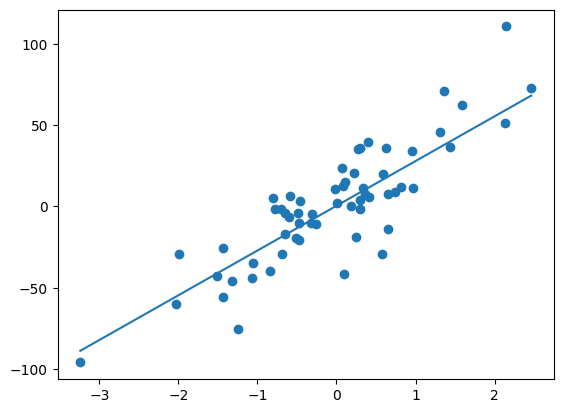

In [2]:
X, y = make_regression(n_samples=300, n_features=1, noise=18, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
reg=LinearRegression().fit(X_train,y_train); pred=reg.predict(X_test)
print("Coefficient:",reg.coef_[0],"Intercept:",reg.intercept_)
print("MAE:",round(mean_absolute_error(y_test,pred),3),"R2:",round(r2_score(y_test,pred),3))
order=np.argsort(X_test[:,0]); plt.scatter(X_test[:,0],y_test); plt.plot(X_test[order,0],pred[order]); plt.show()

## Logistic regression

Logistic regression estimates class probabilities. Scaling is included in the pipeline.

In [3]:
data=load_breast_cancer(as_frame=True); X,y=data.data,data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
clf=make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000)).fit(X_train,y_train)
y_pred=clf.predict(X_test)
print("Accuracy:",round(accuracy_score(y_test,y_pred),4))
print(classification_report(y_test,y_pred,target_names=data.target_names))

Accuracy: 0.9825
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Key takeaways
- Linear regression predicts continuous values.
- Logistic regression is used for classification.
- Choose metrics appropriate to the task.